# 01 · Data sources and data quality

**Goal:** load seven commodities from four free sources, check how trustworthy each source is, and decide which one the screener should use.

| Source | What it gives | Frequency | History |
|---|---|---|---|
| yfinance `=F` tickers | Front-month futures (NG, CL, BZ, GC, SI, HG, ALI) | Daily OHLCV | 2000+ (Brent 2007, ALI 2014) |
| Westmetall | LME official cash and 3-month settlement prices, plus LME stocks | Daily | 2008+ |
| FRED (IMF series) | Gas, oil, copper, aluminium | Monthly average | 1992+ |
| World Bank Pink Sheet | Everything here, incl. gold, silver, EU gas, Japan LNG | Monthly average | 1960+ |

**Why bother with more than one source?** A CFD price is derived from a futures price, and a retail trader sees only one quote. Comparing sources is how you find out whether a chart is showing the market or showing a data problem.

**Westmetall terms (checked 1 Nov 2026):** `robots.txt` has no `Disallow` rules. The imprint (legal notice) says copying or reusing content "in any other electronic format" needs the publisher's consent, and the prices themselves are LME data. So this project scrapes slowly (one page per metal per year, 3 s apart), caches every page in `data/raw/` (git-ignored), and publishes only derived statistics and charts, never the raw price tables. Ask Westmetall for permission before publishing their data.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=UserWarning)
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
from IPython.display import display

from commodities import COMMODITIES, SCREENER, build_panels, load_ohlc, load_price
from commodities.config import TABLES_DIR
from commodities.metrics import log_returns
from commodities.quality import flag_jumps, quality_summary, stale_runs
from commodities import plots

pd.options.display.float_format = "{:,.2f}".format

Matplotlib is building the font cache; this may take a moment.


## 1. One loader for every source

`load_price(commodity, source)` always returns a float Series in the commodity's **standard unit**. For example, COMEX copper (HG=F) is quoted in USD/lb and the registry multiplies it by 2,204.62 so it is directly comparable with the LME's USD/tonne. Swapping a source anywhere in the project is a one-word change.

In [2]:
inventory = pd.DataFrame([
    {"commodity": k, "source": src, "id": s.attrs["id"], "unit": s.attrs["unit"], "freq": s.attrs["freq"],
     "first": s.index[0].date(), "last": s.index[-1].date(), "rows": len(s), "last_value": s.iloc[-1]}
    for k in SCREENER for src in COMMODITIES[k].sources for s in [load_price(k, src)]
])
inventory

,commodity,source,id,unit,freq,first,last,rows,last_value
0,natgas_us,yahoo,NG=F,USD/MMBtu,D,2000-08-30,2026-10-30,6573,2.90
1,natgas_us,fred,PNGASUSUSDM,USD/MMBtu,M,1992-01-01,2026-09-01,417,2.95
2,natgas_us,worldbank,"Natural gas, US",USD/MMBtu,M,1960-01-01,2026-09-01,801,2.95
3,wti,yahoo,CL=F,USD/bbl,D,2000-08-23,2026-10-30,6576,104.12
4,wti,fred,POILWTIUSDM,USD/bbl,M,1992-01-01,2026-09-01,417,97.09
5,wti,worldbank,"Crude oil, WTI",USD/bbl,M,1982-01-01,2026-09-01,537,96.90
6,brent,yahoo,BZ=F,USD/bbl,D,2007-07-30,2026-10-30,4794,113.43
7,brent,fred,POILBREUSDM,USD/bbl,M,1992-01-01,2026-09-01,417,102.02
8,brent,worldbank,"Crude oil, Brent",USD/bbl,M,1960-01-01,2026-09-01,801,116.80
9,gold,yahoo,GC=F,USD/oz,D,2000-08-30,2026-10-30,6568,"3,898.90"


## 2. yfinance continuous futures: what can go wrong

A ticker like `NG=F` is not one contract. It is whichever contract is front month that day, joined end to end. When one contract expires the series switches to the next, and if the next contract is priced differently (normal in seasonal gas, or in a steep oil curve) the chart **jumps on the roll day even though no trader made or lost that money**. Real CFD providers handle the roll differently, so check how Trading 212 rolls each instrument.

Checks below:
- **suspected jumps**: daily moves more than 6 robust standard deviations from normal. The scale is a rolling median absolute deviation (MAD), which one huge day cannot inflate.
- **gaps** longer than a long weekend, and **stale runs** where the price is unchanged for 3+ rows (nothing traded).
- **zero-volume days**: the price printed but no contracts changed hands.
- **non-positive prices**: WTI settled at **−$37.63** on 20 April 2020, when storage at Cushing was full and holders of the expiring contract paid to get rid of it. Log returns are undefined there, so the code masks returns where the previous price was ≤ 0.

In [3]:
ohlc = {k: load_ohlc(k) for k in SCREENER}
quality = pd.DataFrame([quality_summary(ohlc[k], COMMODITIES[k].sources["yahoo"].id) for k in SCREENER])
quality

,first_date,rows,zero_volume_%,zero_volume_last_1y_%,gaps_>4d,stale_runs_>=3,non_positive_prices,suspected_jumps
NG=F,2000-08-30,6573,0.23,0.80,12,0,0,14
CL=F,2000-08-23,6576,0.20,0.80,13,0,1,18
BZ=F,2007-07-30,4794,0.29,1.20,9,2,0,13
GC=F,2000-08-30,6568,6.36,1.20,12,1,0,18
SI=F,2000-08-30,6569,11.34,2.79,12,2,0,19
HG=F,2000-08-30,6572,1.11,0.80,13,2,0,6
ALI=F,2014-05-06,3105,63.09,64.14,3,24,0,48


In [4]:
jumps = {k: flag_jumps(ohlc[k]["Close"]) for k in SCREENER}
print("Share of suspected jumps in the second half of the month (energy front months expire then):")
print({COMMODITIES[k].sources["yahoo"].id: f"{j['late_month'].mean():.0%} of {len(j)}" for k, j in jumps.items() if len(j)})
jumps["natgas_us"].tail(8)

Share of suspected jumps in the second half of the month (energy front months expire then):
{'NG=F': '93% of 14', 'CL=F': '67% of 18', 'BZ=F': '69% of 13', 'GC=F': '61% of 18', 'SI=F': '74% of 19', 'HG=F': '33% of 6', 'ALI=F': '56% of 48'}


,return,robust_z,late_month
Date,,,
2016-10-28,0.12,6.04,True
2018-11-14,0.18,8.45,False
2018-11-15,-0.17,-7.69,True
2022-01-27,0.46,8.43,True
2024-04-29,0.26,6.84,True
2026-01-20,0.26,6.06,True
2026-01-26,0.29,6.44,True
2026-01-29,-0.47,-10.57,True


**Reading it:**
- **NG=F**: 93% of its flagged days fall in the second half of the month, when the front-month contract expires. That points to **rolls**: gas contracts for neighbouring months can be priced very differently (a January contract carries winter risk, a February one less), so the spliced series jumps. The three flags in January 2026 show how messy a winter expiry can be. A real CFD trader takes these moves on margin too, so the scorecard excludes flagged days when measuring *normal* risk and keeps them when measuring *tail* risk.
- **CL=F** has the one non-positive price (April 2020) and its flagged days sit around that episode and other expiries.
- **GC=F and SI=F** have zero-volume rows. That's because the yfinance front month is sometimes a thinly traded delivery month while the liquid contract is a later one. The *price* still tracks the market, so this is a minor issue.
- **ALI=F** is in a different league: most days have zero volume. Section 4 deals with it.

## 3. Do the sources agree? Monthly averages, last 5 years

FRED and the World Bank publish monthly *averages*, so the fair comparison is the monthly average of the daily yfinance price.

In [5]:
rows = []
for k in SCREENER:
    daily = load_price(k, "yahoo").resample("MS").mean()
    for src in ("fred", "worldbank"):
        if src in COMMODITIES[k].sources:
            m = load_price(k, src)
            d = (daily / m - 1).dropna().loc["2021-10":]
            rows.append({"commodity": k, "vs": src, "median_abs_diff_%": 100 * d.abs().median(),
                         "max_abs_diff_%": 100 * d.abs().max(), "worst_month": d.abs().idxmax().strftime("%Y-%m")})
agreement = pd.DataFrame(rows)
agreement

,commodity,vs,median_abs_diff_%,max_abs_diff_%,worst_month
0,natgas_us,fred,0.18,2.98,2026-01
1,natgas_us,worldbank,3.93,43.69,2026-01
2,wti,fred,0.56,3.46,2026-05
3,wti,worldbank,0.16,1.25,2026-09
4,brent,fred,0.17,0.93,2026-07
5,brent,worldbank,1.20,14.90,2026-04
6,gold,worldbank,0.41,1.61,2023-08
7,silver,worldbank,0.16,3.59,2025-12
8,copper,fred,0.85,22.49,2025-07
9,copper,worldbank,0.84,22.49,2025-07


In [6]:
brent = pd.DataFrame({"BZ=F (futures)": load_price("brent", "yahoo").resample("MS").mean(),
                      "FRED/IMF": load_price("brent", "fred"),
                      "World Bank (Dated Brent)": load_price("brent", "worldbank")}).loc["2025-10":]
brent.assign(physical_premium=brent.iloc[:, 2] - brent.iloc[:, 0])

,BZ=F (futures),FRED/IMF,World Bank (Dated Brent),physical_premium
date,,,,
2025-10-01,63.95,63.98,64.70,0.75
2025-11-01,63.68,63.69,63.60,-0.08
2025-12-01,61.63,61.81,62.70,1.07
2026-01-01,64.77,64.59,66.80,2.03
2026-02-01,69.41,69.41,71.10,1.69
2026-03-01,99.60,99.41,103.70,4.10
2026-04-01,102.46,102.81,120.40,17.94
2026-05-01,104.09,103.84,107.50,3.41
2026-06-01,84.62,84.49,85.40,0.78


**Most sources agree within about 1% in a typical month. The worst months are where the lessons are:**
- **Brent vs World Bank (up to 15%).** The World Bank's Brent is **Dated Brent**, the price of physical North Sea cargoes loading in the next few weeks, while BZ=F and the IMF series follow the **futures**. In April and September 2026 physical barrels traded $14–18 above futures: the market was paying up for oil *now* rather than later (steep backwardation).
- **US gas vs World Bank (44% in January 2026).** The World Bank series is the Henry Hub **spot** price. In a cold snap, spot gas for tomorrow can spike while the futures contract for next month barely moves.
- **Copper (22% in July 2025)** and **aluminium (10% in June 2026)**: COMEX (US) prices pulled away from the global LME benchmark. See sections 4–5.

**Trading lesson:** the headline "oil price" in the news may be Dated Brent, but a Brent CFD is priced off the futures. In a supply shock, your CFD can lag the headline.

WTI shows a smaller version of the same thing: the IMF series runs slightly above the front month in spring 2026.

## 4. ALI=F vs LME aluminium

The LME is where the world's aluminium price is set. The **3-month** price is the LME's most liquid benchmark. It is a constant-maturity price (always delivery three months out), so unlike a front-month future it has **no roll jumps**. The **cash** price is for prompt delivery and can spike when nearby supply is squeezed.

In [7]:
def compare(key, start=None):
    y = load_price(key, "yahoo")
    y.attrs["label"] = f"{COMMODITIES[key].sources['yahoo'].id} (COMEX, yfinance)"
    out = {}
    for src in ("lme_cash", "lme_3m"):
        l = load_price(key, src)
        df = pd.concat([y.rename("y"), l.rename("lme")], axis=1, join="inner").loc[start or y.index[0]:]
        rd = df.apply(log_returns).dropna()
        rw = np.log(df.resample("W-FRI").last()).diff().dropna()
        diff = df["y"] / df["lme"] - 1
        out[src] = pd.Series({
            "common_days": len(df),
            "days_only_in_yahoo": len(y.loc[df.index[0]:].index.difference(l.index)),
            "days_only_in_lme": len(l.loc[df.index[0]:].index.difference(y.index)),
            "daily_return_corr": rd.corr().iat[0, 1],
            "weekly_return_corr": rw.corr().iat[0, 1],
            "median_diff_%": 100 * diff.median(),
            "p5_diff_%": 100 * diff.quantile(0.05),
            "p95_diff_%": 100 * diff.quantile(0.95),
            "stale_runs_yahoo": len(stale_runs(df["y"])),
            "stale_runs_lme": len(stale_runs(df["lme"])),
            "suspected_jumps_yahoo": len(flag_jumps(df["y"])),
            "suspected_jumps_lme": len(flag_jumps(df["lme"])),
        })
    by_year = pd.DataFrame({
        "median_diff_vs_3m_%": 100 * (df["y"] / df["lme"] - 1).groupby(df.index.year).median(),
        "daily_corr_vs_3m": rd.groupby(rd.index.year).apply(lambda g: g.corr().iat[0, 1]),
        "weekly_corr_vs_3m": rw.groupby(rw.index.year).apply(lambda g: g.corr().iat[0, 1]),
    })
    l3 = load_price(key, "lme_3m"); l3.attrs["label"] = "LME 3-month (Westmetall)"
    return pd.DataFrame(out), by_year, y, l3

al_summary, al_by_year, ali, lme_al = compare("aluminium")
vol = ohlc["aluminium"]["Volume"]
al_by_year["ALI_zero_volume_%"] = 100 * (vol == 0).groupby(vol.index.year).mean()
display(al_summary)
al_by_year

,lme_cash,lme_3m
common_days,"3,051.00","3,051.00"
days_only_in_yahoo,54.00,54.00
days_only_in_lme,108.00,108.00
daily_return_corr,0.56,0.56
weekly_return_corr,0.75,0.76
median_diff_%,1.87,1.08
p5_diff_%,-3.18,-3.71
p95_diff_%,20.98,19.78
stale_runs_yahoo,21.00,21.00
stale_runs_lme,0.00,0.00


,median_diff_vs_3m_%,daily_corr_vs_3m,weekly_corr_vs_3m,ALI_zero_volume_%
date,,,,
2014,18.29,0.56,0.89,46.11
2015,7.28,0.47,0.69,59.92
2016,4.68,0.57,0.90,18.81
2017,3.99,0.40,0.67,82.66
2018,9.11,0.00,-0.05,100.00
2019,4.14,0.19,0.10,95.24
2020,-0.22,0.57,0.89,88.14
2021,0.45,0.67,0.87,90.08
2022,-0.33,0.67,0.93,58.17


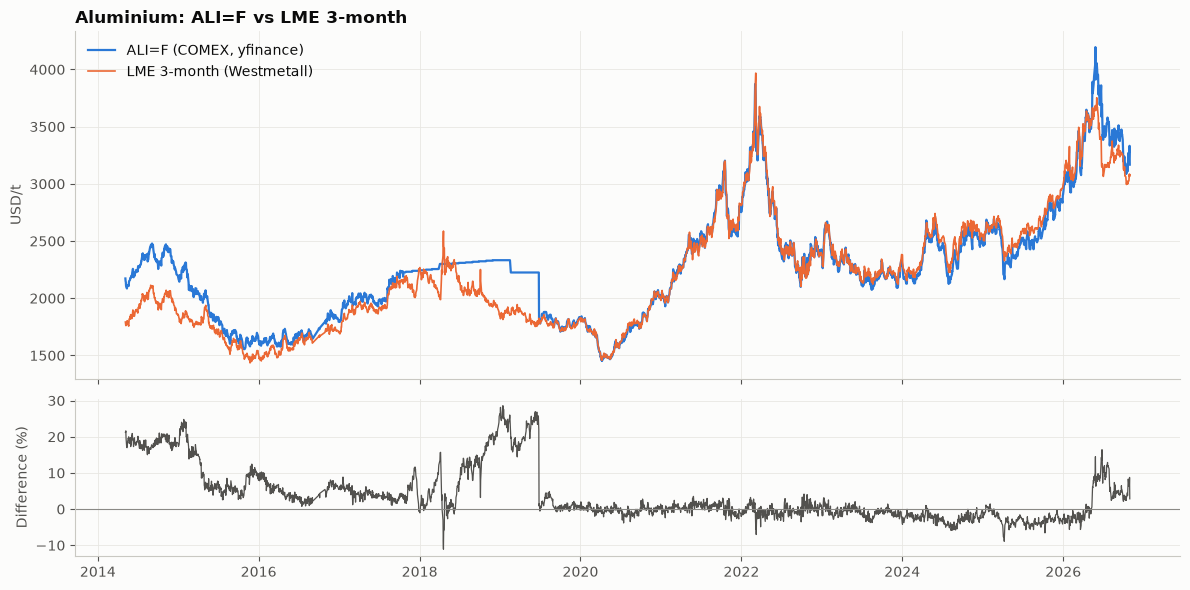

In [8]:
fig = plots.overlay(ali, lme_al, "Aluminium: ALI=F vs LME 3-month", "USD/t")
plots.save(fig, "01_aluminium_ali_vs_lme")

**Verdict on ALI=F: don't use it for analysis.**
- On most days, and on **every** day in 2018, no contracts traded. A price with no trades behind it is an estimate, which is why ALI=F has unchanged-price runs and dozens of suspected jumps while the LME series has almost none.
- The chart shows a **flat line from early 2018 to mid-2019**: no trades for about 18 months, so the "price" just sat there. Its correlation with the LME was zero in 2018–19 at both daily and weekly frequency.
- Before 2020 it traded 4–18% above the LME (median by year), and it moved back to a premium of +5–15% in 2026. That gap looks like a US price (with regional premium and import duties) rather than the global benchmark. It's worth knowing about, but it isn't the market most traders mean by "aluminium".
- LME 3-month is liquid, has no rolls, goes back to 2008 and comes with LME **stock** data, which is a key fundamental for later analysis.

→ The screener uses **`lme_3m`** for aluminium (`DAILY_SOURCE` in `config.py`).

## 5. HG=F vs LME copper

In [9]:
cu_summary, cu_by_year, hg, lme_cu = compare("copper")
display(cu_summary)
cu_by_year

,lme_cash,lme_3m
common_days,"4,652.00","4,652.00"
days_only_in_yahoo,86.00,86.00
days_only_in_lme,108.00,108.00
daily_return_corr,0.56,0.56
weekly_return_corr,0.87,0.88
median_diff_%,0.28,0.08
p5_diff_%,-1.93,-1.97
p95_diff_%,3.57,3.24
stale_runs_yahoo,0.00,0.00
stale_runs_lme,0.00,0.00


,median_diff_vs_3m_%,daily_corr_vs_3m,weekly_corr_vs_3m
date,,,
2008,0.28,0.59,0.94
2009,0.23,0.50,0.88
2010,0.05,0.53,0.90
2011,0.02,0.60,0.96
2012,0.24,0.61,0.84
2013,0.09,0.65,0.88
2014,0.74,0.36,0.87
2015,0.62,0.65,0.85
2016,-0.50,0.64,0.96


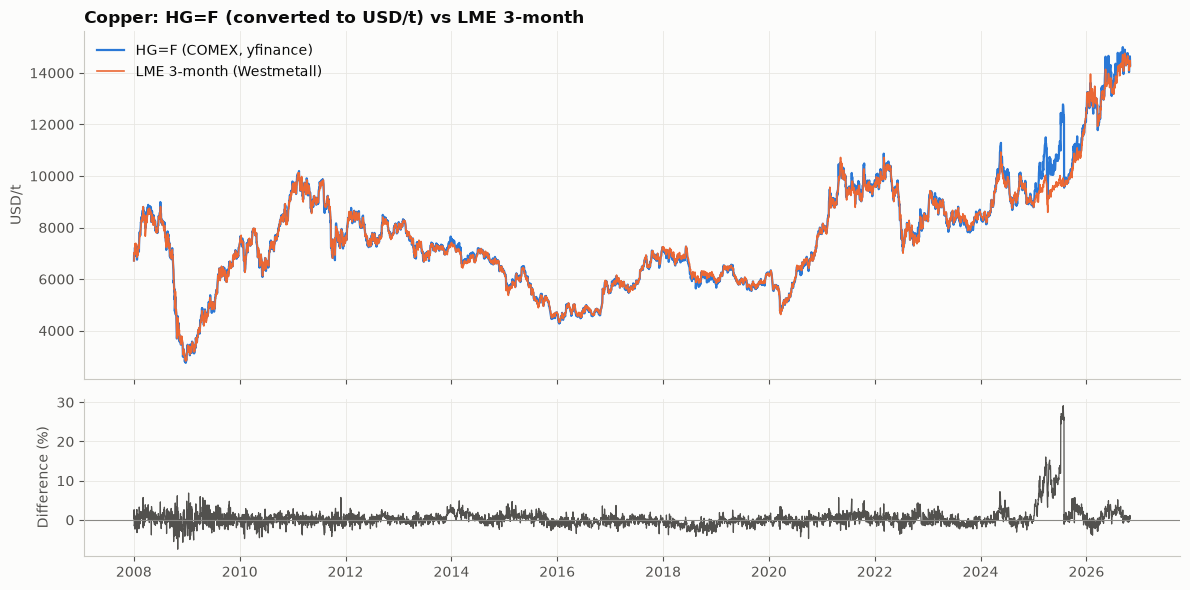

In [10]:
fig = plots.overlay(hg, lme_cu, "Copper: HG=F (converted to USD/t) vs LME 3-month", "USD/t")
plots.save(fig, "01_copper_hg_vs_lme")

**Verdict on HG=F: keep it.**
- It is liquid (almost no zero-volume days or stale runs), goes back to 2000, and normally sits within a fraction of a percent of the LME.
- The daily return correlation of about 0.6 **understates** how closely they track. The LME official price is set around midday London, while COMEX settles about six hours later, so each "daily" return covers a different window. Weekly returns, which overlap almost fully, correlate at about **0.88** (vs 0.56 daily). **Lesson: before calling two markets loosely related, check whether their closing times line up.**
- The exception is **2025**. COMEX climbed to almost **30% above the LME** by July as traders shipped copper into the US ahead of expected import tariffs, then the premium collapsed in a single day once the tariff details were announced. That was a real **arbitrage spread**, not a data error. A trader long HG=F and short LME copper made or lost money on US trade policy, not on copper demand. It is also a reminder that HG=F is a *US* price with US-specific policy risk.

→ The screener uses **HG=F** for copper. Before trading, check which underlying Trading 212's copper CFD tracks; in a tariff episode, COMEX and the LME can diverge by more than a normal daily move.

## 6. Build the processed panels

The daily panel uses `DAILY_SOURCE` (yfinance, with LME 3-month for aluminium). The monthly panel uses the World Bank (longest history, includes gold and silver). Both are saved to `data/processed/` and read by notebooks 02 and 03.

Note that aluminium's LME price is set in London while the other six close in New York. Same-day correlations involving aluminium will therefore be slightly understated, for the reason shown with copper above.

In [11]:
daily, monthly = build_panels(SCREENER)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
quality.to_csv(TABLES_DIR / "01_yahoo_quality.csv")
pd.concat({"aluminium": al_summary, "copper": cu_summary}).to_csv(TABLES_DIR / "01_lme_comparison.csv")
print(daily.shape, monthly.shape)
daily.tail(3)

(6690, 7) (801, 7)


,natgas_us,wti,brent,gold,silver,copper,aluminium
date,,,,,,,
2026-10-28,2.82,102.78,115.32,"4,051.60",53.46,"14,641.98","3,084.00"
2026-10-29,2.95,102.00,114.88,"4,031.40",52.19,"14,508.60","3,064.00"
2026-10-30,2.90,104.12,113.43,"3,898.90",49.28,"14,290.35","3,080.00"
